In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio, geopandas as gpd
from rasterio.windows import from_bounds
from rasterio.enums import Resampling
from rasterio.features import rasterize
from shapely.geometry import box
from skimage.filters import threshold_otsu
from skimage.morphology import disk
from scipy import ndimage as ndi
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (log_loss, roc_curve, precision_recall_curve,
                             roc_auc_score, average_precision_score)
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display

%matplotlib inline
pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:.3f}".format)

SEED = 42
rng = np.random.default_rng(SEED)

BASE_DIR = Path("./case-study/data")
SRC_DIR, VAL_DIR = BASE_DIR / "source_data_to_apply_algorithm", BASE_DIR / "validation_data"
MODIS_SHP = VAL_DIR / "modis.ba.poly.shp"
PRE_SAFE = SRC_DIR / "S2A_MSIL2A_20220702T105631_N0510_R094_T30TXQ_20240701T074946.SAFE"
POST_SAFE = SRC_DIR / "S2B_MSIL2A_20220905T105619_N0510_R094_T30TXQ_20240730T093743.SAFE"

ROI_BUFFER_M = 1500
SCL_INVALID = [0, 1, 3, 8, 9, 10]
CLOUD_BUFFER_PX = 3
BOA_OFFSET = 1000

N_FIT = 300_000
N_SWEEP = 150_000
N_TREES, N_TREES_SWEEP = 100, 40
MIN_LEAF = 20
CONTEXT_PX = 11

OPEN_R, CLOSE_R = 5, 10
TINY_PX = 50
MIN_OBJ_PX = MIN_HOLE_PX = 5000

def to_refl(dn):
    return np.clip((dn - BOA_OFFSET) / 10000.0, 1e-4, None).astype(np.float32)

def nd(a, b):
    return (a - b) / (a + b)

def threshold_map(d, t, valid):
    with np.errstate(invalid="ignore"):
        return ((d > t) & valid).astype(np.uint8)

def mask_rgb(rgb, valid, fill=0.85):
    out = rgb.copy()
    out[~valid] = fill
    return out

def cmap_bad(name):
    cm = plt.get_cmap(name).copy()
    cm.set_bad("lightgrey")
    return cm

In [2]:
def find_band(safe_path, band_id, resolution):
    matches = (list(Path(safe_path).glob(f"**/IMG_DATA/R{resolution}/*_{band_id}_{resolution}.jp2"))
               or list(Path(safe_path).glob(f"**/*_{band_id}*.jp2")))
    if not matches:
        raise FileNotFoundError(f"{band_id} not found in {safe_path}")
    return matches[0]

BANDS = {"B02": "10m", "B03": "10m", "B04": "10m", "B08": "10m", "B11": "20m", "B12": "20m"}
SAFES = {"pre": PRE_SAFE, "post": POST_SAFE}
PATH = {(b, d): find_band(s, b, res) for d, s in SAFES.items() for b, res in BANDS.items()}
SCL_PATH = {d: find_band(s, "SCL", "20m") for d, s in SAFES.items()}

ems_files = list(VAL_DIR.glob("**/*observedEventA*.shp")) or [p for p in VAL_DIR.glob("**/*.shp") if p.name != MODIS_SHP.name]
gdfs = [gpd.read_file(f) for f in ems_files]
ems = gpd.GeoDataFrame(pd.concat(gdfs, ignore_index=True), crs=gdfs[0].crs)
with rasterio.open(PATH["B08", "pre"]) as src:
    raster_crs = src.crs
    minx, miny, maxx, maxy = ems.to_crs(raster_crs).total_bounds
    ROI = (minx - ROI_BUFFER_M, miny - ROI_BUFFER_M, maxx + ROI_BUFFER_M, maxy + ROI_BUFFER_M)
    win_transform = rasterio.windows.transform(from_bounds(*ROI, transform=src.transform), src.transform)

def read_roi(path, target_shape=None, bnds=None, resampling=Resampling.bilinear):
    with rasterio.open(path) as src:
        win = from_bounds(*(bnds or ROI), transform=src.transform)
        kw = {} if target_shape is None else dict(out_shape=target_shape, resampling=resampling)
        return src.read(1, window=win, **kw).astype(np.float32)

SHAPE = read_roi(PATH["B08", "pre"]).shape
print(f"ROI: {SHAPE[1]} x {SHAPE[0]} px")

def cloud_valid_mask(bnds, shape):
    bad = np.zeros(shape, dtype=bool)
    for d in ("pre", "post"):
        bad |= np.isin(read_roi(SCL_PATH[d], target_shape=shape, bnds=bnds, resampling=Resampling.nearest), SCL_INVALID)
    if CLOUD_BUFFER_PX > 0:
        bad = ndi.binary_dilation(bad, structure=disk(CLOUD_BUFFER_PX).astype(bool))
    return ~bad

valid = cloud_valid_mask(ROI, SHAPE)
R = {f"{b}_{d}": to_refl(read_roi(p, SHAPE)) for (b, d), p in PATH.items()}

ROI: 3054 x 2101 px


In [3]:
roi_poly = gpd.GeoSeries([box(*ROI)], crs=raster_crs)
os.environ["SHAPE_RESTORE_SHX"] = "YES"
gdf_modis = gpd.read_file(MODIS_SHP, bbox=tuple(roi_poly.to_crs("EPSG:4326").total_bounds))
if gdf_modis.crs is None:
    gdf_modis = gdf_modis.set_crs("EPSG:4326")
gdf_target = gpd.clip(gdf_modis.to_crs(raster_crs), roi_poly.union_all())
shapes = [(g, 1) for g in gdf_target.geometry if g is not None and not g.is_empty]
target_raw = rasterize(shapes, out_shape=SHAPE, transform=win_transform, fill=0, dtype=np.uint8)
print(f"MODIS polygons in ROI: {len(gdf_target)}")

MODIS polygons in ROI: 7


masked: 18.42% of the ROI
burned target pixels: 1,577,372 (548,195 lost under clouds)


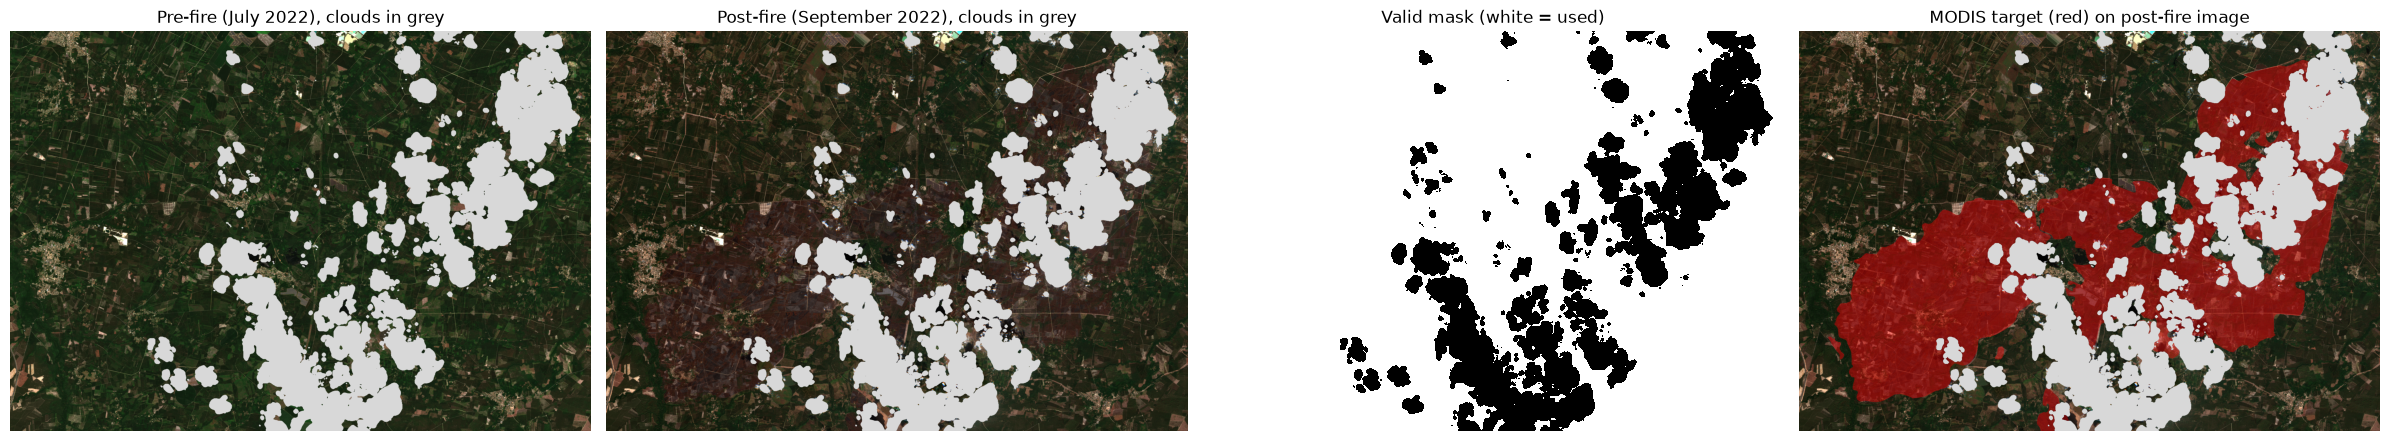

In [4]:
assert valid.shape == SHAPE == target_raw.shape, "grid mismatch"
target = target_raw.copy()
target[~valid] = 0
print(f"masked: {100 * (~valid).mean():.2f}% of the ROI")
print(f"burned target pixels: {int(target.sum()):,} ({int(target_raw.sum() - target.sum()):,} lost under clouds)")

def rgb(date):
    return mask_rgb(np.clip(np.stack([R[f"{c}_{date}"] for c in ("B04", "B03", "B02")], -1) / 0.25, 0, 1), valid)
pre_rgb, post_rgb = rgb("pre"), rgb("post")

fig, axes = plt.subplots(1, 4, figsize=(24, 6.5))
axes[0].imshow(pre_rgb)
axes[0].set_title("Pre-fire (July 2022), clouds in grey")
axes[1].imshow(post_rgb)
axes[1].set_title("Post-fire (September 2022), clouds in grey")
axes[2].imshow(valid, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[2].set_title("Valid mask (white = used)")
axes[3].imshow(post_rgb)
axes[3].imshow(target, cmap=ListedColormap(["none", "red"]), alpha=0.4)
axes[3].set_title("MODIS target (red) on post-fire image")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

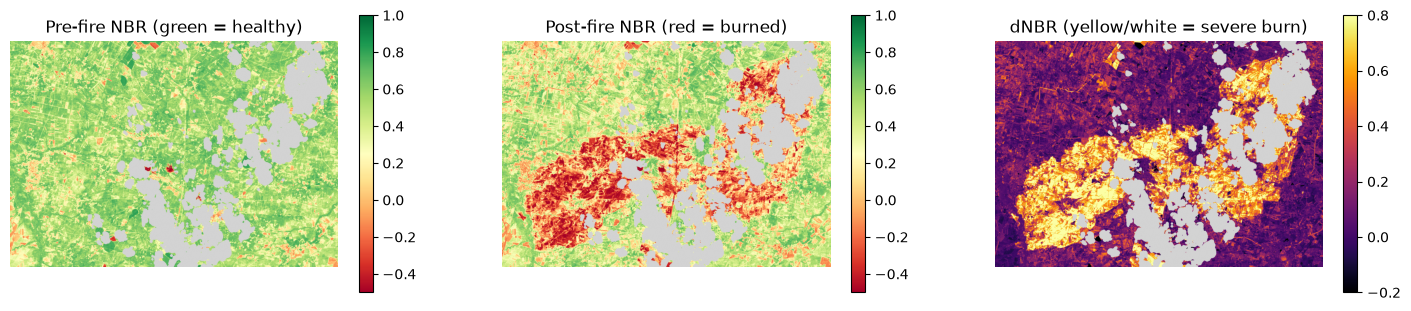

In [5]:
def local_stats(a, valid, size):
    m = valid.astype(np.float32)
    a0 = np.where(valid, a, 0).astype(np.float32)
    n = np.maximum(ndi.uniform_filter(m, size), 1e-6)
    mean = ndi.uniform_filter(a0, size) / n
    std = np.sqrt(np.maximum(ndi.uniform_filter(a0 ** 2, size) / n - mean ** 2, 0))
    return mean.astype(np.float32), std.astype(np.float32)

F = {}
for d in ("pre", "post"):
    F[f"NBR_{d}"] = nd(R[f"B08_{d}"], R[f"B12_{d}"])
    F[f"NDVI_{d}"] = nd(R[f"B08_{d}"], R[f"B04_{d}"])
F["dNBR"] = F["NBR_pre"] - F["NBR_post"]
F["dNDVI"] = F["NDVI_pre"] - F["NDVI_post"]
F["dNBR_mean"], F["dNBR_std"] = local_stats(F["dNBR"], valid, CONTEXT_PX)
RAW_BANDS = [f"{b}_{d}" for d in ("pre", "post") for b in BANDS]
F.update({k: R[k] for k in RAW_BANDS})
for k in F:
    F[k][~valid] = np.nan
dnbr = F["dNBR"]
dnbr_flat = dnbr.ravel()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (k, vmin, vmax, cm, t) in zip(axes, [("NBR_pre", -0.5, 1, "RdYlGn", "Pre-fire NBR (green = healthy)"),
                                            ("NBR_post", -0.5, 1, "RdYlGn", "Post-fire NBR (red = burned)"),
                                            ("dNBR", -0.2, 0.8, "inferno", "dNBR (yellow/white = severe burn)")]):
    im = ax.imshow(F[k], cmap=cmap_bad(cm), vmin=vmin, vmax=vmax)
    ax.set_title(t)
    ax.axis("off")
    plt.colorbar(im, ax=ax, shrink=0.6)
plt.show()

Otsu threshold: 0.3818


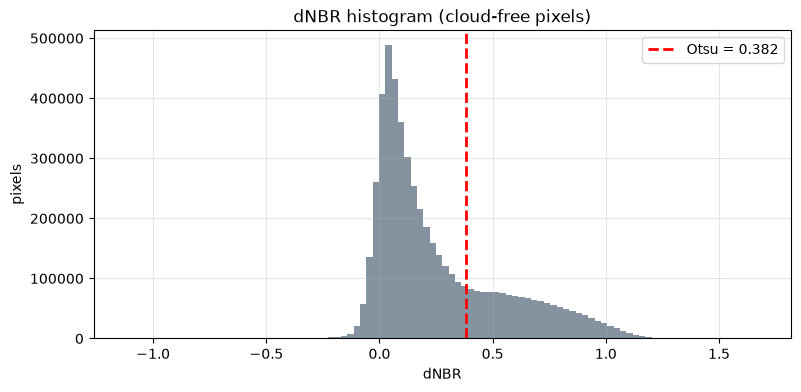

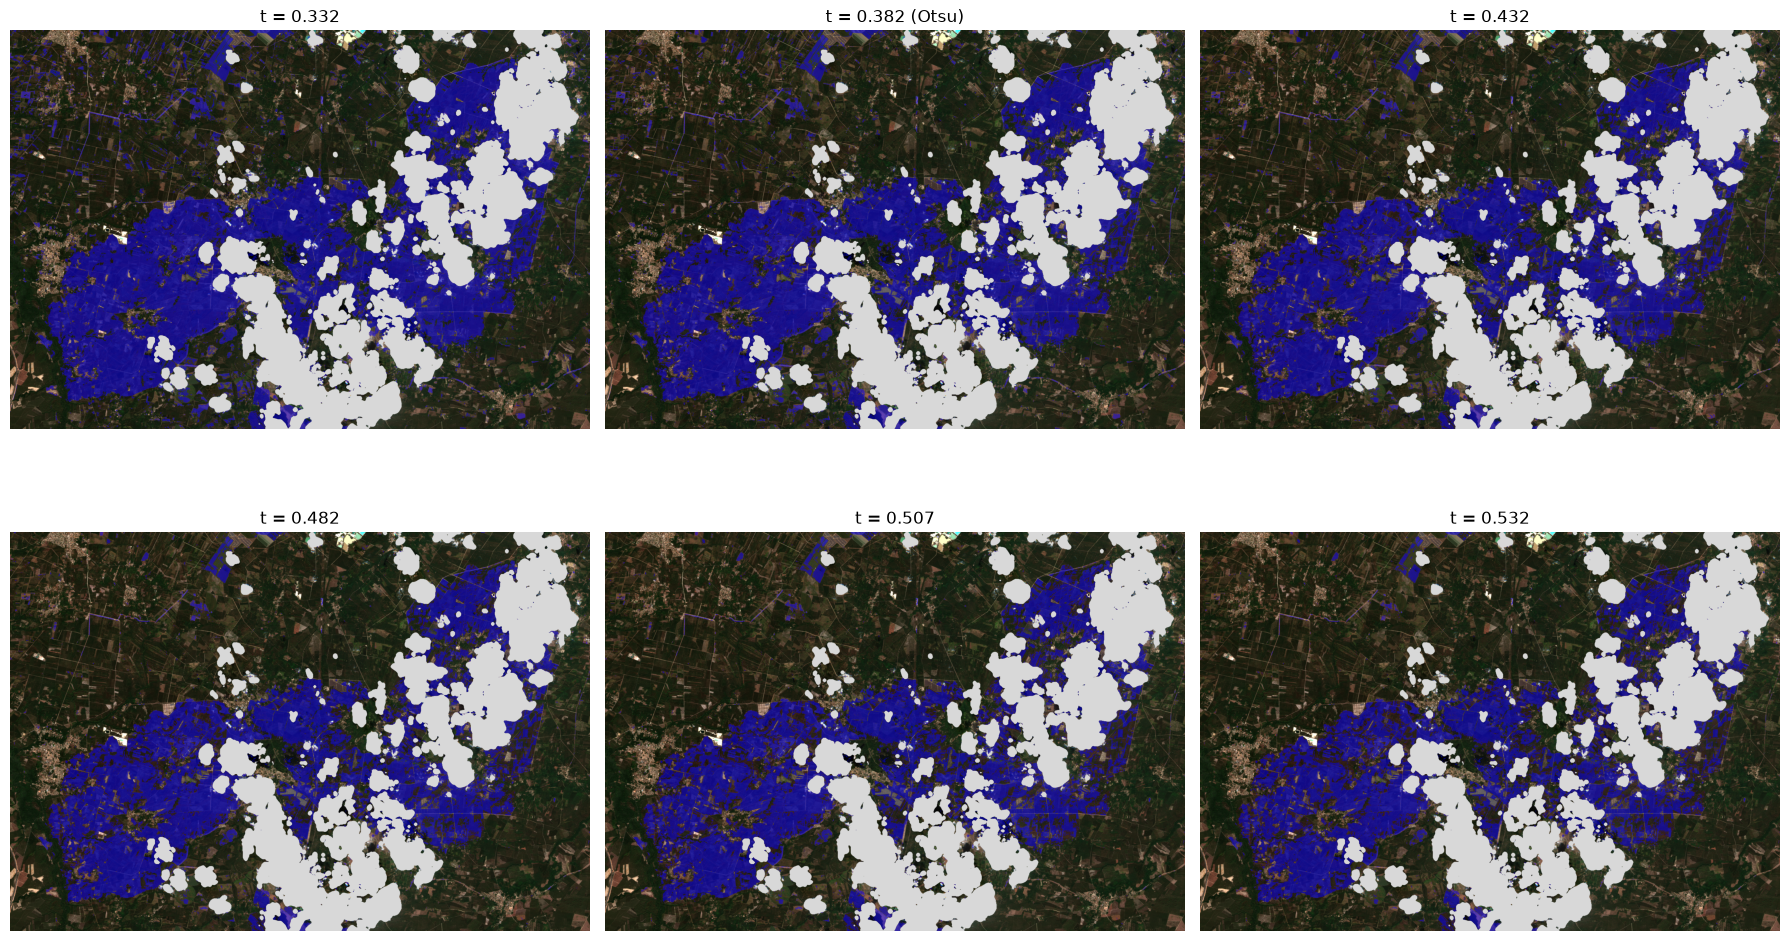

In [6]:
otsu_thresh = threshold_otsu(dnbr[valid])
otsu_raw = threshold_map(dnbr, otsu_thresh, valid)
print(f"Otsu threshold: {otsu_thresh:.4f}")

plt.figure(figsize=(9, 4))
plt.hist(dnbr[valid], bins=100, color="slategray", alpha=0.85)
plt.axvline(otsu_thresh, color="red", ls="--", lw=2, label=f"Otsu = {otsu_thresh:.3f}")
plt.xlabel("dNBR")
plt.ylabel("pixels")
plt.title("dNBR histogram (cloud-free pixels)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

ths = otsu_thresh + np.array([-0.05, 0, 0.05, 0.10, 0.125, 0.15])
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, t in zip(axes.flat, ths):
    ax.imshow(post_rgb)
    ax.imshow(threshold_map(dnbr, t, valid), cmap=ListedColormap(["none", "blue"]), alpha=0.5)
    ax.set_title(f"t = {t:.3f}" + (" (Otsu)" if t == otsu_thresh else ""))
    ax.axis("off")
plt.tight_layout()
plt.show()

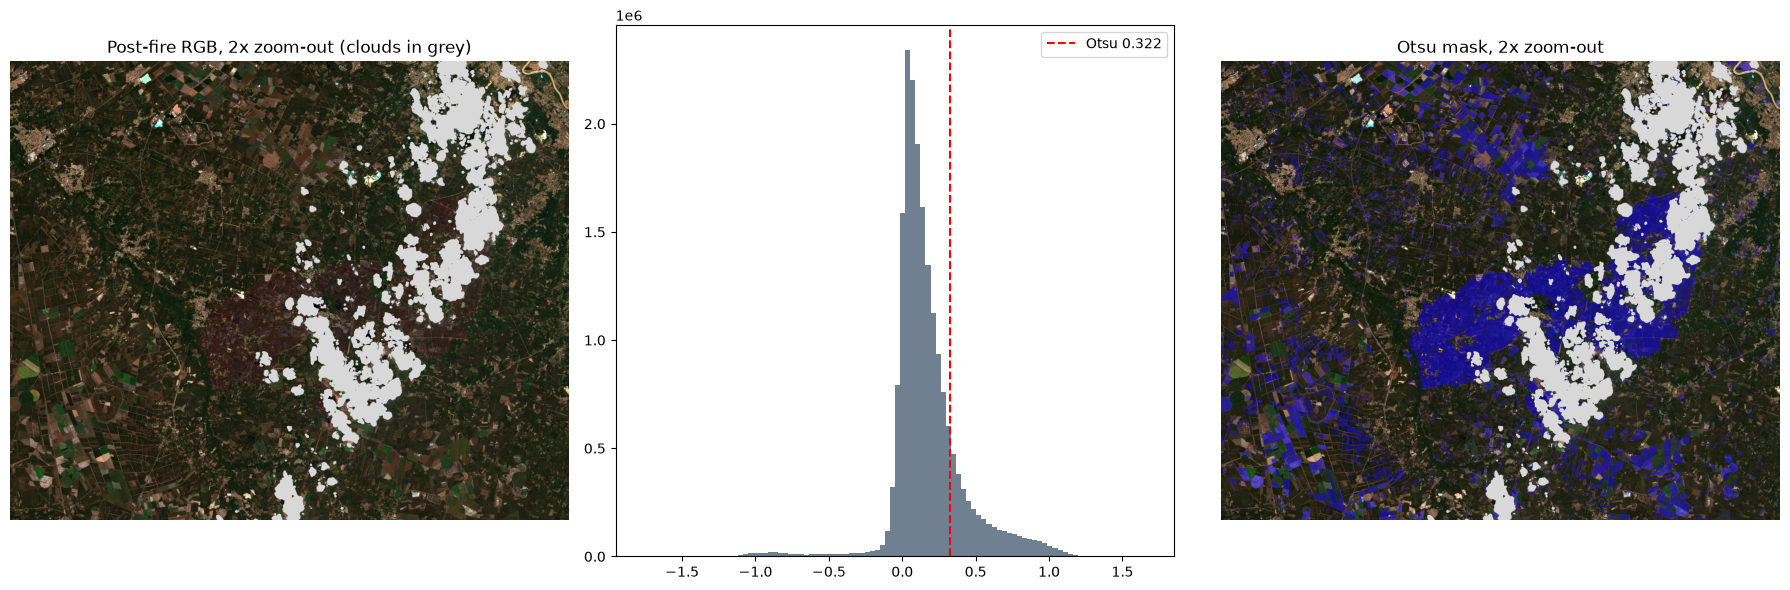

In [7]:
cx, cy, w, h = (ROI[0] + ROI[2]) / 2, (ROI[1] + ROI[3]) / 2, ROI[2] - ROI[0], ROI[3] - ROI[1]
bz = (cx - w, cy - h, cx + w, cy + h)
shape_z = read_roi(PATH["B08", "pre"], bnds=bz).shape
rz = lambda key: to_refl(read_roi(PATH[key], target_shape=shape_z, bnds=bz))
valid_z = cloud_valid_mask(bz, shape_z)
dnbr_z = nd(rz(("B08", "pre")), rz(("B12", "pre"))) - nd(rz(("B08", "post")), rz(("B12", "post")))
dnbr_z[~valid_z] = np.nan
otsu_z = threshold_otsu(dnbr_z[valid_z])
zoom_rgb = mask_rgb(np.clip(np.stack([rz((c, "post")) for c in ("B04", "B03", "B02")], -1) / 0.25, 0, 1), valid_z)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(zoom_rgb)
axes[0].set_title("Post-fire RGB, 2x zoom-out (clouds in grey)")
axes[1].hist(dnbr_z[valid_z], bins=100, color="slategray")
axes[1].axvline(otsu_z, color="r", ls="--", label=f"Otsu {otsu_z:.3f}")
axes[1].legend()
axes[2].imshow(zoom_rgb)
axes[2].imshow(threshold_map(dnbr_z, otsu_z, valid_z), cmap=ListedColormap(["none", "blue"]), alpha=0.5)
axes[2].set_title("Otsu mask, 2x zoom-out")
for i in (0, 2):
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [8]:
H, W = SHAPE
left = np.zeros(SHAPE, dtype=bool)
left[:, : W // 2] = True
FOLDS = {"A (train LEFT / val RIGHT)": (left, ~left),
         "B (train RIGHT / val LEFT)": (~left, left)}
y = target.ravel()

def pix(region):
    return np.flatnonzero((region & valid).ravel())

def pick(idx, n):
    return idx if len(idx) <= n else rng.choice(idx, n, replace=False)

def get_X(names, idx):
    return np.column_stack([F[n].ravel()[idx] for n in names]).astype(np.float32)

def scores(y_true, y_pred, s=None):
    yt, yp = np.asarray(y_true).astype(bool), np.asarray(y_pred).astype(bool)
    tp, fp, fn = (yt & yp).sum(), (~yt & yp).sum(), (yt & ~yp).sum()
    out = {"IoU": tp / max(tp + fp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
           "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1)}
    if s is not None and 0 < yt.sum() < len(yt):
        out["ROC-AUC"], out["PR-AUC"] = roc_auc_score(yt, s), average_precision_score(yt, s)
    return out

for k, (tr, va) in FOLDS.items():
    itr, iva = pix(tr), pix(va)
    print(f"{k:30s} train {len(itr):>9,d} px (burned {y[itr].mean():6.1%}) | val {len(iva):>9,d} px (burned {y[iva].mean():6.1%})")

A (train LEFT / val RIGHT)     train 2,931,132 px (burned  27.5%) | val 2,303,503 px (burned  33.4%)
B (train RIGHT / val LEFT)     train 2,303,503 px (burned  33.4%) | val 2,931,132 px (burned  27.5%)


In [9]:
def best_iou_threshold(score, y_true):
    fpr, tpr, thr = roc_curve(y_true, score)
    P, N = y_true.sum(), (1 - y_true).sum()
    return thr[np.argmax(tpr * P / (P + fpr * N))]

tuned_thr = {}
thr_flat = np.zeros(H * W, dtype=np.uint8)
for k, (tr, va) in FOLDS.items():
    itr, iva = pix(tr), pix(va)
    tuned_thr[k] = best_iou_threshold(dnbr_flat[itr], y[itr])
    thr_flat[iva] = dnbr_flat[iva] >= tuned_thr[k]
    print(f"{k:30s} tuned {tuned_thr[k]:.3f}  otsu {otsu_thresh:.3f}")
thr_raw = thr_flat.reshape(SHAPE)

A (train LEFT / val RIGHT)     tuned 0.382  otsu 0.382
B (train RIGHT / val LEFT)     tuned 0.292  otsu 0.382


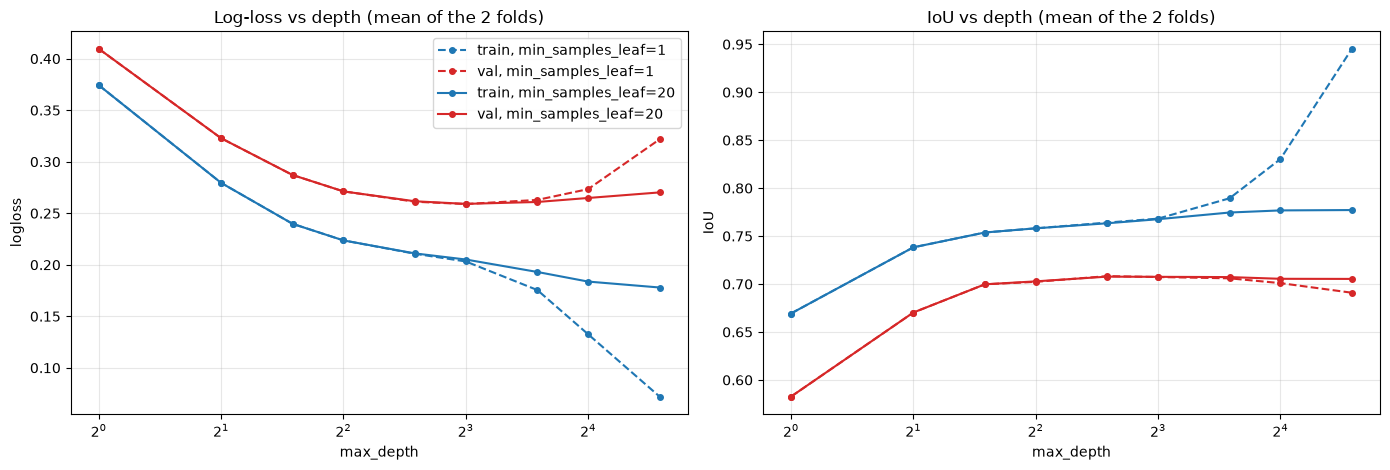

best depth 8, kept depth 6


In [10]:
BASE_FEATS = ["NBR_pre", "NBR_post", "dNBR"]
SWEEP_IDX = {k: (pick(pix(tr), N_SWEEP), pick(pix(va), N_SWEEP)) for k, (tr, va) in FOLDS.items()}

def fold_data(names):
    return {k: (get_X(names, itr), y[itr], get_X(names, iva), y[iva]) for k, (itr, iva) in SWEEP_IDX.items()}

def fit_rf(X, y_, depth, n_trees=N_TREES, leaf=MIN_LEAF):
    return RandomForestClassifier(n_estimators=n_trees, max_depth=depth, min_samples_leaf=leaf,
                                  n_jobs=-1, random_state=SEED).fit(X, y_)

def ll(y_, p):
    return log_loss(y_, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1])

DEPTHS = [1, 2, 3, 4, 6, 8, 12, 16, 24]
base_data = fold_data(BASE_FEATS)
rows = []
for k, (Xtr, ytr, Xva, yva) in base_data.items():
    for leaf in (1, MIN_LEAF):
        for d in DEPTHS:
            rf = fit_rf(Xtr, ytr, d, N_TREES_SWEEP, leaf)
            for part, (X_, y_) in (("train", (Xtr, ytr)), ("val", (Xva, yva))):
                p = rf.predict_proba(X_)[:, 1]
                rows.append(dict(fold=k, leaf=leaf, depth=d, part=part, logloss=ll(y_, p), IoU=scores(y_, p > 0.5)["IoU"]))
sweep = pd.DataFrame(rows)
m = sweep.groupby(["leaf", "part", "depth"])[["logloss", "IoU"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric in zip(axes, ("logloss", "IoU")):
    for leaf, ls in ((1, "--"), (MIN_LEAF, "-")):
        for part, c in (("train", "tab:blue"), ("val", "tab:red")):
            s = m[(m.leaf == leaf) & (m.part == part)]
            ax.plot(s.depth, s[metric], ls=ls, c=c, marker="o", ms=4, label=f"{part}, min_samples_leaf={leaf}")
    ax.set_xscale("log", base=2)
    ax.set_xlabel("max_depth")
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
axes[0].set_title("Log-loss vs depth (mean of the 2 folds)")
axes[1].set_title("IoU vs depth (mean of the 2 folds)")
axes[0].legend()
plt.tight_layout()
plt.show()

v = sweep[(sweep.leaf == MIN_LEAF) & (sweep.part == "val")].groupby("depth").logloss.mean()
BEST_DEPTH = int(v[v <= v.min() * 1.02].index.min())
print(f"best depth {int(v.idxmin())}, kept depth {BEST_DEPTH}")

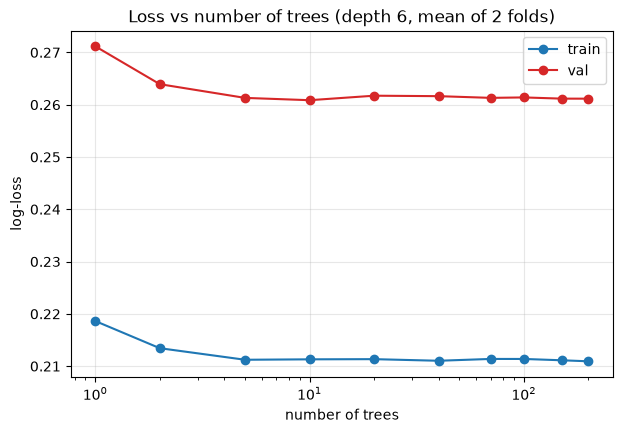

IoU train  IoU val   gap  loss train  loss val  verdict
config                         fold                                                         
original (depth 10, leaf 1)    A         0.766    0.703 0.063       0.183     0.265  overfit
                               B         0.786    0.710 0.076       0.200     0.254  overfit
regularised (depth 6, leaf 20) A         0.754    0.703 0.051       0.203     0.271  overfit
                               B         0.773    0.715 0.058       0.219     0.252  overfit

In [11]:
CHECK = [1, 2, 5, 10, 20, 40, 70, 100, 150, 200]
rows = []
for k, (Xtr, ytr, Xva, yva) in base_data.items():
    rf = fit_rf(Xtr, ytr, BEST_DEPTH, max(CHECK), MIN_LEAF)
    XY = {"train": (Xtr, ytr), "val": (Xva, yva)}
    acc = {p: np.zeros(len(XY[p][1])) for p in XY}
    for i, tree in enumerate(rf.estimators_, 1):
        for p in XY:
            pr = tree.predict_proba(XY[p][0])
            acc[p] += pr[:, 1] if pr.shape[1] == 2 else 0
        if i in CHECK:
            for p in XY:
                rows.append(dict(fold=k, trees=i, part=p, logloss=ll(XY[p][1], acc[p] / i)))
tc = pd.DataFrame(rows).groupby(["part", "trees"]).logloss.mean().reset_index()
plt.figure(figsize=(7, 4.5))
for part, c in (("train", "tab:blue"), ("val", "tab:red")):
    s = tc[tc.part == part]
    plt.plot(s.trees, s.logloss, marker="o", c=c, label=part)
plt.xscale("log")
plt.xlabel("number of trees")
plt.ylabel("log-loss")
plt.grid(alpha=0.3)
plt.legend()
plt.title(f"Loss vs number of trees (depth {BEST_DEPTH}, mean of 2 folds)")
plt.show()

cfgs = {"original (depth 10, leaf 1)": (10, 1), f"regularised (depth {BEST_DEPTH}, leaf {MIN_LEAF})": (BEST_DEPTH, MIN_LEAF)}
rows = []
for name, (d, leaf) in cfgs.items():
    for k, (Xtr, ytr, Xva, yva) in base_data.items():
        rf = fit_rf(Xtr, ytr, d, N_TREES, leaf)
        ptr, pva = rf.predict_proba(Xtr)[:, 1], rf.predict_proba(Xva)[:, 1]
        a, b = scores(ytr, ptr > 0.5)["IoU"], scores(yva, pva > 0.5)["IoU"]
        rows.append({"config": name, "fold": k.split()[0], "IoU train": a, "IoU val": b, "gap": a - b,
                     "loss train": ll(ytr, ptr), "loss val": ll(yva, pva)})
cfg_table = pd.DataFrame(rows)
cfg_table["verdict"] = np.where(cfg_table["gap"] > 0.05, "overfit", "ok")
display(cfg_table.set_index(["config", "fold"]))

,n_features,IoU train,IoU val,PR-AUC val,loss val,gap
set,,,,,,
dNBR only,1.000,0.745,0.694,0.914,0.281,0.051
NBR pre/post/d (orig.),3.000,0.763,0.708,0.931,0.262,0.056
+ local context,5.000,0.846,0.789,0.962,0.192,0.056
+ NDVI,6.000,0.777,0.712,0.933,0.254,0.064
+ NDVI + raw bands,18.000,0.841,0.764,0.954,0.207,0.077


kept feature set: + local context


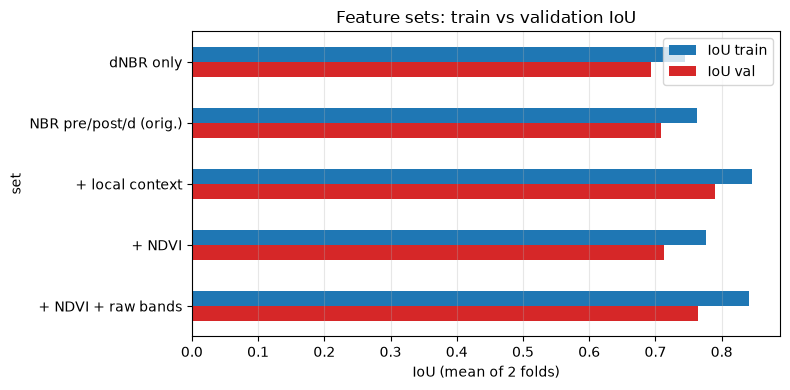

In [12]:
FEATURE_SETS = {
    "dNBR only": ["dNBR"],
    "NBR pre/post/d (orig.)": ["NBR_pre", "NBR_post", "dNBR"],
    "+ local context": ["NBR_pre", "NBR_post", "dNBR", "dNBR_mean", "dNBR_std"],
    "+ NDVI": ["NBR_pre", "NBR_post", "dNBR", "NDVI_pre", "NDVI_post", "dNDVI"],
    "+ NDVI + raw bands": ["NBR_pre", "NBR_post", "dNBR", "NDVI_pre", "NDVI_post", "dNDVI"] + RAW_BANDS,
}
TOL = 0.01
rows = []
for name, names in FEATURE_SETS.items():
    for k, (Xtr, ytr, Xva, yva) in fold_data(names).items():
        rf = fit_rf(Xtr, ytr, BEST_DEPTH, N_TREES_SWEEP, MIN_LEAF)
        ptr, pva = rf.predict_proba(Xtr)[:, 1], rf.predict_proba(Xva)[:, 1]
        sv = scores(yva, pva > 0.5, pva)
        rows.append({"set": name, "n_features": len(names), "IoU train": scores(ytr, ptr > 0.5)["IoU"],
                     "IoU val": sv["IoU"], "PR-AUC val": sv["PR-AUC"], "loss val": ll(yva, pva)})
fs = pd.DataFrame(rows).groupby("set", sort=False).mean()
fs["gap"] = fs["IoU train"] - fs["IoU val"]
BEST_SET = fs[fs["IoU val"] >= fs["IoU val"].max() - TOL].sort_values("n_features").index[0]
display(fs)
print(f"kept feature set: {BEST_SET}")

ax = fs[["IoU train", "IoU val"]].plot.barh(figsize=(8, 4), color=["tab:blue", "tab:red"])
ax.invert_yaxis()
ax.set_xlabel("IoU (mean of 2 folds)")
ax.set_title("Feature sets: train vs validation IoU")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

final RF: + local context, depth 6, leaf 20, 100 trees


,IoU train,IoU val,gap,verdict
fold,,,,
A (train LEFT / val RIGHT),0.834,0.798,0.036,ok
B (train RIGHT / val LEFT),0.857,0.787,0.070,overfit


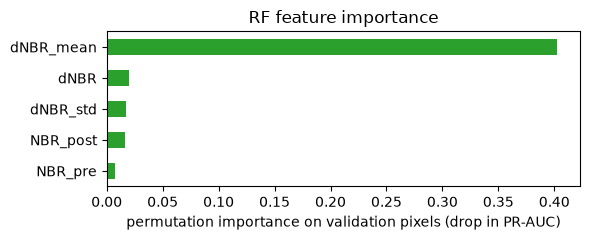

In [13]:
names = FEATURE_SETS[BEST_SET]
proba = np.full(H * W, np.nan, dtype=np.float32)
rows, imps = [], []
for k, (tr, va) in FOLDS.items():
    itr, iva = pick(pix(tr), N_FIT), pix(va)
    Xtr, Xva = get_X(names, itr), get_X(names, iva)
    rf = fit_rf(Xtr, y[itr], BEST_DEPTH, N_TREES, MIN_LEAF)
    proba[iva] = rf.predict_proba(Xva)[:, 1]
    iou_tr = scores(y[itr], rf.predict_proba(Xtr)[:, 1] > 0.5)["IoU"]
    iou_va = scores(y[iva], proba[iva] > 0.5)["IoU"]
    rows.append({"fold": k, "IoU train": iou_tr, "IoU val": iou_va, "gap": iou_tr - iou_va})
    sub = pick(np.arange(len(iva)), 50_000)
    pi = permutation_importance(rf, Xva[sub], y[iva][sub], scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=-1)
    imps.append(pd.Series(pi.importances_mean, index=names))
gap_table = pd.DataFrame(rows).set_index("fold")
gap_table["verdict"] = np.where(gap_table["gap"] > 0.05, "overfit", "ok")
print(f"final RF: {BEST_SET}, depth {BEST_DEPTH}, leaf {MIN_LEAF}, {N_TREES} trees")
display(gap_table)

rf_raw = (np.nan_to_num(proba, nan=0.0) > 0.5).reshape(SHAPE).astype(np.uint8)
pd.concat(imps, axis=1).mean(axis=1).sort_values().plot.barh(figsize=(6, max(2.5, 0.35 * len(names))), color="tab:green")
plt.xlabel("permutation importance on validation pixels (drop in PR-AUC)")
plt.title("RF feature importance")
plt.tight_layout()
plt.show()

In [14]:
def remove_small(m, min_size, keep_border=False):
    lab, n = ndi.label(m)
    if n == 0:
        return m
    keep = np.bincount(lab.ravel()) >= min_size
    keep[0] = False
    if keep_border:
        border = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
        keep[border[border > 0]] = True
    return keep[lab]

def morph_clean(mask, valid):
    m = remove_small((mask > 0) & valid, TINY_PX)
    pad = max(OPEN_R, CLOSE_R) + 1
    m = np.pad(m, pad, mode="edge")
    m = ndi.binary_opening(m, structure=disk(OPEN_R).astype(bool))
    m = ndi.binary_closing(m, structure=disk(CLOSE_R).astype(bool))
    m = m[pad:-pad, pad:-pad] & valid
    m = remove_small(m, MIN_OBJ_PX)
    m = (m | ~remove_small(~m, MIN_HOLE_PX, keep_border=True)) & valid
    return m.astype(np.uint8)

masks = {}
for name, raw in (("Otsu", otsu_raw), ("dNBR threshold (tuned on train)", thr_raw), ("Random Forest", rf_raw)):
    masks[name] = raw
    masks[name + " + morphology"] = morph_clean(raw, valid)
print({k: int(ndi.label(v)[1]) for k, v in masks.items()})

{'Otsu': 7049, 'Otsu + morphology': 12, 'dNBR threshold (tuned on train)': 10115, 'dNBR threshold (tuned on train) + morphology': 15, 'Random Forest': 1896, 'Random Forest + morphology': 13}


,IoU,F1,Precision,Recall,ROC-AUC,PR-AUC
method,,,,,,
Otsu,0.725,0.841,0.892,0.795,0.950,0.907
Otsu + morphology,0.778,0.875,0.968,0.799,NaN,NaN
dNBR threshold (tuned on train),0.700,0.824,0.817,0.830,0.950,0.907
dNBR threshold (tuned on train) + morphology,0.799,0.888,0.944,0.839,NaN,NaN
Random Forest,0.792,0.884,0.889,0.879,0.972,0.947
Random Forest + morphology,0.873,0.932,0.954,0.911,NaN,NaN


IoU per fold


split,A,B,pooled
method,,,
Otsu,0.723,0.727,0.725
Otsu + morphology,0.722,0.830,0.778
dNBR threshold (tuned on train),0.723,0.683,0.700
dNBR threshold (tuned on train) + morphology,0.722,0.866,0.799
Random Forest,0.798,0.787,0.792
Random Forest + morphology,0.846,0.897,0.873


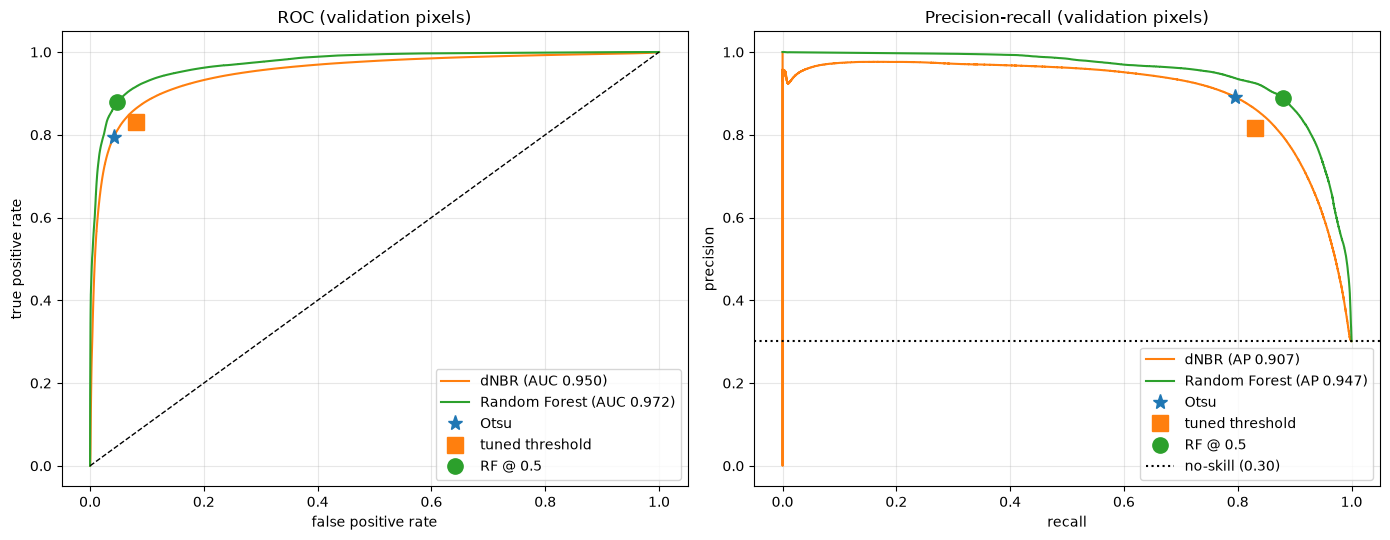

In [15]:
SCORE = {"Otsu": dnbr_flat, "dNBR threshold (tuned on train)": dnbr_flat, "Random Forest": proba}
VAL_IDX = {k: pix(va) for k, (tr, va) in FOLDS.items()}
VAL_IDX["pooled"] = np.concatenate(list(VAL_IDX.values()))

rows = []
for name, m in masks.items():
    mf = m.ravel()
    for split, iv in VAL_IDX.items():
        s = SCORE[name][iv] if name in SCORE else None
        rows.append({"method": name, "split": split.split()[0], **scores(y[iv], mf[iv], s)})
summary = pd.DataFrame(rows)
display(summary[summary.split == "pooled"].set_index("method").drop(columns="split"))
print("IoU per fold")
display(summary.pivot(index="method", columns="split", values="IoU").loc[list(masks)])
summary.to_csv("results_summary.csv", index=False)

iv = VAL_IDX["pooled"]
yt = y[iv].astype(bool)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for nm, s, c in (("dNBR", dnbr_flat[iv], "tab:orange"), ("Random Forest", proba[iv], "tab:green")):
    fpr, tpr, _ = roc_curve(yt, s)
    pr, rc, _ = precision_recall_curve(yt, s)
    ax[0].plot(fpr, tpr, c=c, label=f"{nm} (AUC {roc_auc_score(yt, s):.3f})")
    ax[1].plot(rc, pr, c=c, label=f"{nm} (AP {average_precision_score(yt, s):.3f})")
for nm, m, mk in (("Otsu", otsu_raw, "*"), ("tuned threshold", thr_raw, "s"), ("RF @ 0.5", rf_raw, "o")):
    p = m.ravel()[iv].astype(bool)
    tp, fp = (p & yt).sum(), (p & ~yt).sum()
    ax[0].plot(fp / (~yt).sum(), tp / yt.sum(), mk, ms=11, label=nm)
    ax[1].plot(tp / yt.sum(), tp / max(tp + fp, 1), mk, ms=11, label=nm)
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].axhline(yt.mean(), ls=":", c="k", label=f"no-skill ({yt.mean():.2f})")
ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC (validation pixels)")
ax[1].set(xlabel="recall", ylabel="precision", title="Precision-recall (validation pixels)")
for a in ax:
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

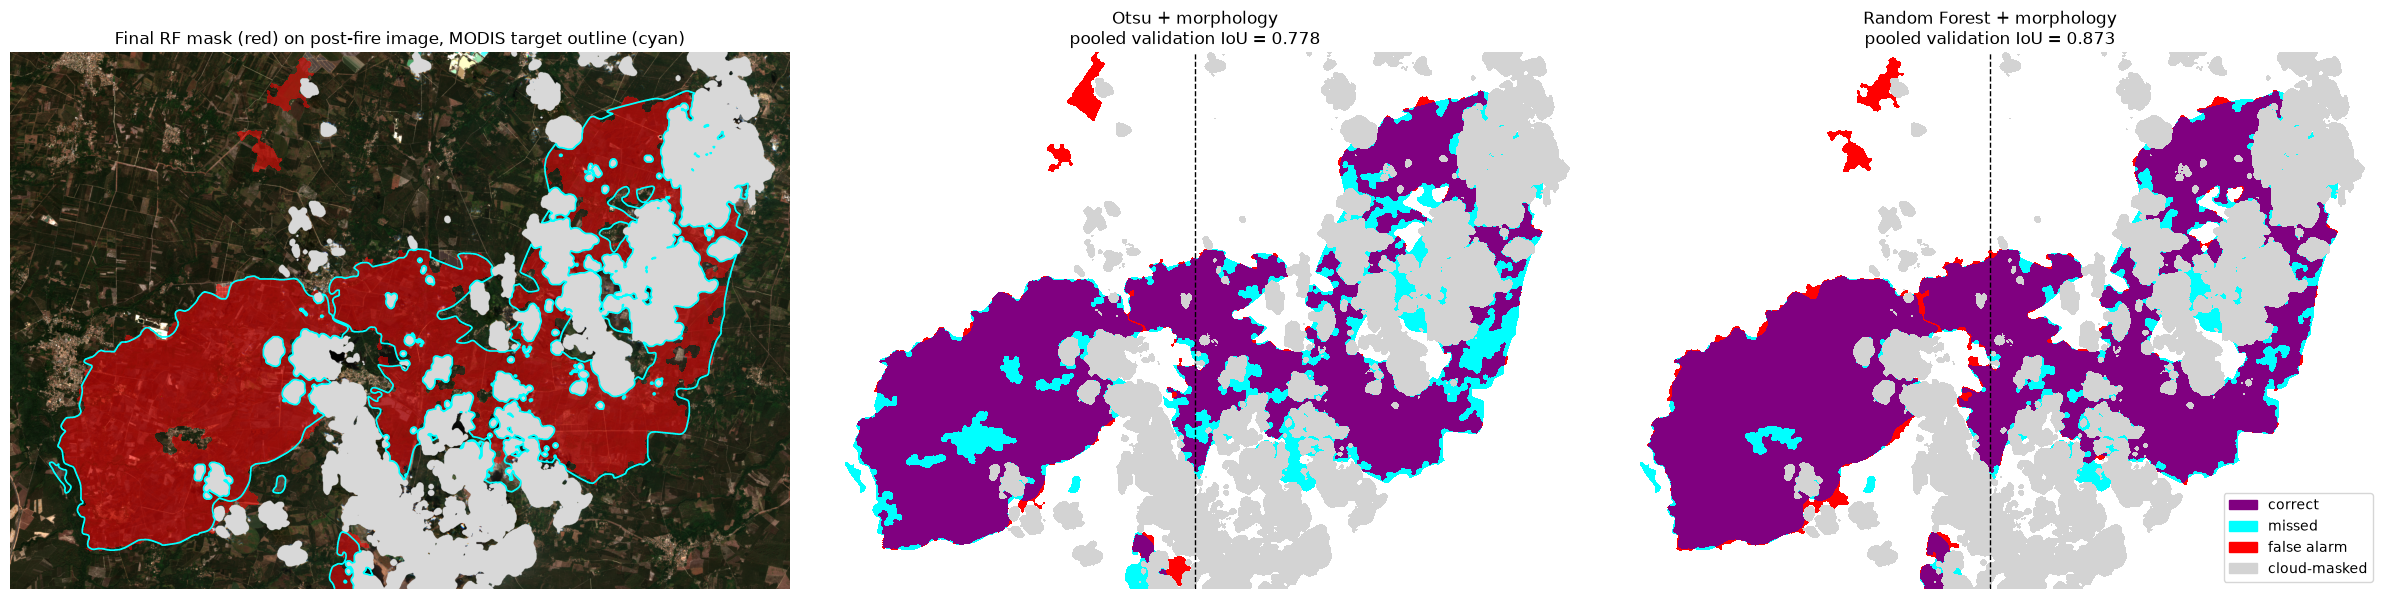

In [16]:
def error_map(ax, pred, title):
    ov = target.astype(int) + 2 * pred.astype(int)
    cm = ListedColormap(["white", "cyan", "red", "purple"])
    cm.set_bad("lightgrey")
    ax.imshow(np.ma.masked_where(~valid, ov), cmap=cm, vmin=0, vmax=3, interpolation="nearest")
    ax.axvline(W // 2, color="k", lw=1, ls="--")
    ax.set_title(title)
    ax.axis("off")

pooled = summary[summary.split == "pooled"].set_index("method")["IoU"]
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
axes[0].imshow(post_rgb)
axes[0].imshow(masks["Random Forest + morphology"], cmap=ListedColormap(["none", "red"]), alpha=0.5, interpolation="nearest")
axes[0].contour(target, levels=[0.5], colors="cyan", linewidths=1.2)
axes[0].set_title("Final RF mask (red) on post-fire image, MODIS target outline (cyan)")
axes[0].axis("off")
for ax, nm in zip(axes[1:], ("Otsu + morphology", "Random Forest + morphology")):
    error_map(ax, masks[nm], f"{nm}\npooled validation IoU = {pooled[nm]:.3f}")
axes[2].legend(handles=[Patch(color="purple", label="correct"), Patch(color="cyan", label="missed"),
                        Patch(color="red", label="false alarm"), Patch(color="lightgrey", label="cloud-masked")], loc="lower right")
plt.tight_layout()
plt.show()